# Seasonal Agriculture Performance Analysis

## Major Project

### VOIS AICTE Batch 1 2026–2027

This project analyzes agricultural performance across different seasons, crops, geographical regions, environmental conditions, resource usage, and economic factors.

The analysis focuses on identifying seasonal patterns, comparing agricultural performance, investigating relationships between environmental conditions and agricultural outcomes, and developing evidence-based insights and recommendations.

## 1. Problem Statement

Agricultural activities are influenced by seasonal variations in environmental conditions, farming practices, resource availability, and market conditions. As a result, agricultural performance may differ from one season to another.

Raw agricultural data does not clearly explain how agricultural performance changes across seasons or what patterns can be observed under different seasonal conditions.

Therefore, this project analyzes the agricultural dataset to investigate seasonal differences in agricultural performance by identifying meaningful patterns, trends, relationships, and variations within the available data.

## 2. Objectives

The main objectives of this project are:

- Explore and understand the agricultural dataset.
- Clean and prepare the data for analysis.
- Analyze agricultural performance across different seasons.
- Identify important seasonal patterns and trends.
- Compare crop performance across seasons.
- Investigate relationships between environmental conditions and agricultural outcomes.
- Analyze differences in resource usage across seasons.
- Examine seasonal economic performance.
- Identify unusual patterns and significant observations.
- Create meaningful data visualizations.
- Develop evidence-based conclusions and recommendations.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

%matplotlib inline
print("libraries imported successfully")

libraries imported successfully


In [2]:
df = pd.read_csv("agriculture_dataset.csv")
print("dataset imported successfully")

dataset imported successfully


In [3]:
df.head()

,Farm_ID,State,District,Crop,Season,Farm_Area_Hectares,Rainfall_mm,Avg_Temperature_C,Humidity_pct,Sunlight_Hours_Day,...,Seed_Quality_Score,Yield_Tonnes_Ha,Production_Tonnes,Market_Price_INR_Tonne,Total_Cost_INR,Revenue_INR,Profit_INR,Water_Used_m3,Water_Efficiency_t_per_1000m3,Disease_Pest_Risk_pct
0,SF10001,Andhra Pradesh,Rajkot,Wheat,Kharif,0.53,486.4,24.3,69.1,5.8,...,0.76,2.46,1.30,23700,42662,30810,-11852,237,5.485,55.3
1,SF10002,Maharashtra,Nalgonda,Maize,Kharif,6.53,855.4,25.7,78.4,5.1,...,0.94,0.30,1.96,20613,492351,40401,-451950,4953,0.396,49.9
2,SF10003,Telangana,Warangal,Pulses,Rabi,4.86,455.6,23.9,56.4,10.3,...,0.98,0.52,2.53,75283,315210,190466,-124744,1275,1.984,33.7
3,SF10004,Telangana,Indore,Rice,Kharif,4.50,753.2,29.7,65.2,6.3,...,0.74,1.84,8.28,24244,296444,200740,-95704,3834,2.160,50.6
4,SF10005,Karnataka,Ludhiana,Maize,Zaid,4.21,101.6,34.1,55.2,6.5,...,0.90,2.21,9.30,20818,337959,193607,-144352,3287,2.829,32.3


## 3. Dataset Exploration

Before performing detailed analysis, the dataset is explored to understand its structure, variables, data types, and overall characteristics.

In [4]:
print("Number of rows:", df.shape[0])
print("Number of columns:", df.shape[1])

Number of rows: 4000
Number of columns: 28


In [5]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 4000 entries, 0 to 3999
Data columns (total 28 columns):
 #   Column                         Non-Null Count  Dtype  
---  ------                         --------------  -----  
 0   Farm_ID                        4000 non-null   object 
 1   State                          4000 non-null   object 
 2   District                       4000 non-null   object 
 3   Crop                           4000 non-null   object 
 4   Season                         4000 non-null   object 
 5   Farm_Area_Hectares             4000 non-null   float64
 6   Rainfall_mm                    3952 non-null   float64
 7   Avg_Temperature_C              4000 non-null   float64
 8   Humidity_pct                   4000 non-null   float64
 9   Sunlight_Hours_Day             4000 non-null   float64
 10  Soil_pH                        4000 non-null   float64
 11  Soil_Moisture_pct              3960 non-null   float64
 12  Nitrogen_kg_ha                 4000 non-null   f

In [6]:
df.describe(include="all")

,Farm_ID,State,District,Crop,Season,Farm_Area_Hectares,Rainfall_mm,Avg_Temperature_C,Humidity_pct,Sunlight_Hours_Day,...,Seed_Quality_Score,Yield_Tonnes_Ha,Production_Tonnes,Market_Price_INR_Tonne,Total_Cost_INR,Revenue_INR,Profit_INR,Water_Used_m3,Water_Efficiency_t_per_1000m3,Disease_Pest_Risk_pct
count,4000,4000,4000,4000,4000,4000.000000,3952.000000,4000.00000,4000.000000,4000.000000,...,4000.000000,3968.000000,4000.000000,4000.000000,4.000000e+03,4.000000e+03,4.000000e+03,4000.000000,4000.000000,4000.000000
unique,4000,8,10,8,3,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
top,SF10001,Andhra Pradesh,Ludhiana,Rice,Kharif,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
freq,1,529,427,690,1779,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
mean,NaN,NaN,NaN,NaN,NaN,7.888265,601.152657,26.81890,63.210500,7.323050,...,0.826138,5.270595,43.246210,44714.166250,5.263036e+05,6.378600e+05,1.115565e+05,6045.570250,5.385214,46.365875
std,NaN,NaN,NaN,NaN,NaN,4.223764,288.925025,3.81818,11.960834,1.121186,...,0.101747,13.361398,126.880521,30266.161922,2.944191e+05,6.369747e+05,5.450819e+05,5572.944306,8.838101,12.424417
min,NaN,NaN,NaN,NaN,NaN,0.500000,80.000000,16.20000,25.000000,3.500000,...,0.650000,0.300000,0.150000,2594.000000,2.682600e+04,6.107000e+03,-1.019223e+06,128.000000,0.135000,5.000000
25%,NaN,NaN,NaN,NaN,NaN,4.260000,370.200000,23.90000,54.775000,6.600000,...,0.740000,1.050000,5.020000,21429.250000,2.745775e+05,2.075172e+05,-1.487318e+05,2268.750000,1.661000,37.300000
50%,NaN,NaN,NaN,NaN,NaN,7.895000,582.000000,26.90000,63.000000,7.300000,...,0.830000,1.740000,11.770000,25913.000000,5.190825e+05,4.568305e+05,3.673000e+03,4435.000000,2.937500,46.400000
75%,NaN,NaN,NaN,NaN,NaN,11.650000,834.950000,29.60000,71.900000,8.100000,...,0.910000,2.840000,24.355000,68279.000000,7.619965e+05,8.368748e+05,2.161878e+05,7829.750000,5.150250,54.900000


In [7]:
df.columns

Index(['Farm_ID', 'State', 'District', 'Crop', 'Season', 'Farm_Area_Hectares',
       'Rainfall_mm', 'Avg_Temperature_C', 'Humidity_pct',
       'Sunlight_Hours_Day', 'Soil_pH', 'Soil_Moisture_pct', 'Nitrogen_kg_ha',
       'Phosphorus_kg_ha', 'Potassium_kg_ha', 'Irrigation_Method',
       'Fertilizer_kg_ha', 'Pesticide_Litre_ha', 'Seed_Quality_Score',
       'Yield_Tonnes_Ha', 'Production_Tonnes', 'Market_Price_INR_Tonne',
       'Total_Cost_INR', 'Revenue_INR', 'Profit_INR', 'Water_Used_m3',
       'Water_Efficiency_t_per_1000m3', 'Disease_Pest_Risk_pct'],
      dtype='object')

In [8]:
missing_values = df.isnull().sum()

missing_values[missing_values > 0]
print("Total missing values:", df.isnull().sum().sum())

Total missing values: 120


In [9]:
print("Number of duplicate rows:", df.duplicated().sum())
df[df.duplicated()]

Number of duplicate rows: 0


,Farm_ID,State,District,Crop,Season,Farm_Area_Hectares,Rainfall_mm,Avg_Temperature_C,Humidity_pct,Sunlight_Hours_Day,...,Seed_Quality_Score,Yield_Tonnes_Ha,Production_Tonnes,Market_Price_INR_Tonne,Total_Cost_INR,Revenue_INR,Profit_INR,Water_Used_m3,Water_Efficiency_t_per_1000m3,Disease_Pest_Risk_pct


In [10]:
print("Seasons:")
print(df["Season"].unique())


Seasons:
['Kharif' 'Rabi' 'Zaid']


In [11]:
print("\nCrops:")
print(df["Crop"].unique())


Crops:
['Wheat' 'Maize' 'Pulses' 'Rice' 'Cotton' 'Chilli' 'Groundnut' 'Sugarcane']


In [12]:
print(df.columns.tolist())

['Farm_ID', 'State', 'District', 'Crop', 'Season', 'Farm_Area_Hectares', 'Rainfall_mm', 'Avg_Temperature_C', 'Humidity_pct', 'Sunlight_Hours_Day', 'Soil_pH', 'Soil_Moisture_pct', 'Nitrogen_kg_ha', 'Phosphorus_kg_ha', 'Potassium_kg_ha', 'Irrigation_Method', 'Fertilizer_kg_ha', 'Pesticide_Litre_ha', 'Seed_Quality_Score', 'Yield_Tonnes_Ha', 'Production_Tonnes', 'Market_Price_INR_Tonne', 'Total_Cost_INR', 'Revenue_INR', 'Profit_INR', 'Water_Used_m3', 'Water_Efficiency_t_per_1000m3', 'Disease_Pest_Risk_pct']


In [13]:
df.head()

,Farm_ID,State,District,Crop,Season,Farm_Area_Hectares,Rainfall_mm,Avg_Temperature_C,Humidity_pct,Sunlight_Hours_Day,...,Seed_Quality_Score,Yield_Tonnes_Ha,Production_Tonnes,Market_Price_INR_Tonne,Total_Cost_INR,Revenue_INR,Profit_INR,Water_Used_m3,Water_Efficiency_t_per_1000m3,Disease_Pest_Risk_pct
0,SF10001,Andhra Pradesh,Rajkot,Wheat,Kharif,0.53,486.4,24.3,69.1,5.8,...,0.76,2.46,1.30,23700,42662,30810,-11852,237,5.485,55.3
1,SF10002,Maharashtra,Nalgonda,Maize,Kharif,6.53,855.4,25.7,78.4,5.1,...,0.94,0.30,1.96,20613,492351,40401,-451950,4953,0.396,49.9
2,SF10003,Telangana,Warangal,Pulses,Rabi,4.86,455.6,23.9,56.4,10.3,...,0.98,0.52,2.53,75283,315210,190466,-124744,1275,1.984,33.7
3,SF10004,Telangana,Indore,Rice,Kharif,4.50,753.2,29.7,65.2,6.3,...,0.74,1.84,8.28,24244,296444,200740,-95704,3834,2.160,50.6
4,SF10005,Karnataka,Ludhiana,Maize,Zaid,4.21,101.6,34.1,55.2,6.5,...,0.90,2.21,9.30,20818,337959,193607,-144352,3287,2.829,32.3


In [14]:
print("\nIrrigation Methods:")
print(df["Irrigation_Method"].unique())


Irrigation Methods:
['Drip' 'Flood' 'Rainfed' 'Sprinkler']


In [15]:
df.dtypes

Farm_ID                           object
State                             object
District                          object
Crop                              object
Season                            object
Farm_Area_Hectares               float64
Rainfall_mm                      float64
Avg_Temperature_C                float64
Humidity_pct                     float64
Sunlight_Hours_Day               float64
Soil_pH                          float64
Soil_Moisture_pct                float64
Nitrogen_kg_ha                   float64
Phosphorus_kg_ha                 float64
Potassium_kg_ha                  float64
Irrigation_Method                 object
Fertilizer_kg_ha                 float64
Pesticide_Litre_ha               float64
Seed_Quality_Score               float64
Yield_Tonnes_Ha                  float64
Production_Tonnes                float64
Market_Price_INR_Tonne             int64
Total_Cost_INR                     int64
Revenue_INR                        int64
Profit_INR      

In [16]:
df.isnull().sum()
df.duplicated().sum()

np.int64(0)

In [17]:
numeric_columns = df.select_dtypes(include=np.number).columns

print("Numerical columns:")
print(numeric_columns.tolist())
df[numeric_columns].describe().T

Numerical columns:
['Farm_Area_Hectares', 'Rainfall_mm', 'Avg_Temperature_C', 'Humidity_pct', 'Sunlight_Hours_Day', 'Soil_pH', 'Soil_Moisture_pct', 'Nitrogen_kg_ha', 'Phosphorus_kg_ha', 'Potassium_kg_ha', 'Fertilizer_kg_ha', 'Pesticide_Litre_ha', 'Seed_Quality_Score', 'Yield_Tonnes_Ha', 'Production_Tonnes', 'Market_Price_INR_Tonne', 'Total_Cost_INR', 'Revenue_INR', 'Profit_INR', 'Water_Used_m3', 'Water_Efficiency_t_per_1000m3', 'Disease_Pest_Risk_pct']


,count,mean,std,min,25%,50%,75%,max
Farm_Area_Hectares,4000.0,7.888265,4.223764,0.500,4.260,7.8950,11.65000,15.00
Rainfall_mm,3952.0,601.152657,288.925025,80.000,370.200,582.0000,834.95000,1395.20
Avg_Temperature_C,4000.0,26.818900,3.818180,16.200,23.900,26.9000,29.60000,39.70
Humidity_pct,4000.0,63.210500,11.960834,25.000,54.775,63.0000,71.90000,95.00
Sunlight_Hours_Day,4000.0,7.323050,1.121186,3.500,6.600,7.3000,8.10000,11.00
Soil_pH,4000.0,6.701010,0.641461,5.200,6.260,6.6900,7.14000,8.40
Soil_Moisture_pct,3960.0,26.508232,6.712484,8.000,21.700,26.4000,31.30000,47.00
Nitrogen_kg_ha,4000.0,120.250825,31.216452,40.000,98.500,120.1000,141.22500,220.00
Phosphorus_kg_ha,4000.0,57.781850,17.015074,15.000,46.200,57.5000,69.40000,120.00
Potassium_kg_ha,4000.0,104.760050,27.742681,30.000,86.200,105.1000,123.60000,200.00


In [18]:
categorical_columns = df.select_dtypes(include="object").columns

print("Categorical columns:")
print(categorical_columns.tolist())
for col in categorical_columns:
    print("\n", col)
    print(df[col].value_counts())

Categorical columns:
['Farm_ID', 'State', 'District', 'Crop', 'Season', 'Irrigation_Method']

 Farm_ID
Farm_ID
SF10001    1
SF10002    1
SF10003    1
SF10004    1
SF10005    1
          ..
SF13996    1
SF13997    1
SF13998    1
SF13999    1
SF14000    1
Name: count, Length: 4000, dtype: int64

 State
State
Andhra Pradesh    529
Telangana         516
Maharashtra       512
Madhya Pradesh    497
Karnataka         489
Gujarat           488
Tamil Nadu        485
Punjab            484
Name: count, dtype: int64

 District
District
Ludhiana    427
Warangal    422
Nalgonda    415
Erode       403
Rajkot      401
Krishna     393
Indore      392
Guntur      390
Raichur     386
Nashik      371
Name: count, dtype: int64

 Crop
Crop
Rice         690
Wheat        614
Maize        551
Cotton       508
Pulses       496
Groundnut    424
Chilli       412
Sugarcane    305
Name: count, dtype: int64

 Season
Season
Kharif    1779
Rabi      1627
Zaid       594
Name: count, dtype: int64

 Irrigation_Method
Irr

In [19]:
df = df.drop_duplicates()

print("Duplicate records removed.")
print("New dataset shape:", df.shape)

Duplicate records removed.
New dataset shape: (4000, 28)


### Duplicate Records

The dataset was checked for duplicate records. No duplicate rows were found, so all observations were retained for further analysis.

In [20]:
for col in numeric_columns:
    if df[col].isnull().sum() > 0:
        df[col] = df[col].fillna(df[col].median())

print("Missing numerical values handled.")

Missing numerical values handled.


In [21]:
df.isnull().sum()

Farm_ID                          0
State                            0
District                         0
Crop                             0
Season                           0
Farm_Area_Hectares               0
Rainfall_mm                      0
Avg_Temperature_C                0
Humidity_pct                     0
Sunlight_Hours_Day               0
Soil_pH                          0
Soil_Moisture_pct                0
Nitrogen_kg_ha                   0
Phosphorus_kg_ha                 0
Potassium_kg_ha                  0
Irrigation_Method                0
Fertilizer_kg_ha                 0
Pesticide_Litre_ha               0
Seed_Quality_Score               0
Yield_Tonnes_Ha                  0
Production_Tonnes                0
Market_Price_INR_Tonne           0
Total_Cost_INR                   0
Revenue_INR                      0
Profit_INR                       0
Water_Used_m3                    0
Water_Efficiency_t_per_1000m3    0
Disease_Pest_Risk_pct            0
dtype: int64

In [22]:
print("Dataset shape:", df.shape)
print("Total missing values:", df.isnull().sum().sum())
print("Total duplicate rows:", df.duplicated().sum())

Dataset shape: (4000, 28)
Total missing values: 0
Total duplicate rows: 0


In [23]:
columns_to_check = [
    "Farm_Area_Hectares",
    "Rainfall_mm",
    "Avg_Temperature_C",
    "Humidity_pct",
    "Sunlight_Hours_Day",
    "Nitrogen_kg_ha",
    "Phosphorus_kg_ha",
    "Potassium_kg_ha",
    "Fertilizer_kg_ha",
    "Pesticide_Litre_ha",
    "Yield_Tonnes_Ha",
    "Production_Tonnes",
    "Market_Price_INR_Tonne",
    "Total_Cost_INR",
    "Revenue_INR",
    "Water_Used_m3"
]

for col in columns_to_check:
    print(col, ":", (df[col] < 0).sum(), "negative values")

Farm_Area_Hectares : 0 negative values
Rainfall_mm : 0 negative values
Avg_Temperature_C : 0 negative values
Humidity_pct : 0 negative values
Sunlight_Hours_Day : 0 negative values
Nitrogen_kg_ha : 0 negative values
Phosphorus_kg_ha : 0 negative values
Potassium_kg_ha : 0 negative values
Fertilizer_kg_ha : 0 negative values
Pesticide_Litre_ha : 0 negative values
Yield_Tonnes_Ha : 0 negative values
Production_Tonnes : 0 negative values
Market_Price_INR_Tonne : 0 negative values
Total_Cost_INR : 0 negative values
Revenue_INR : 0 negative values
Water_Used_m3 : 0 negative values


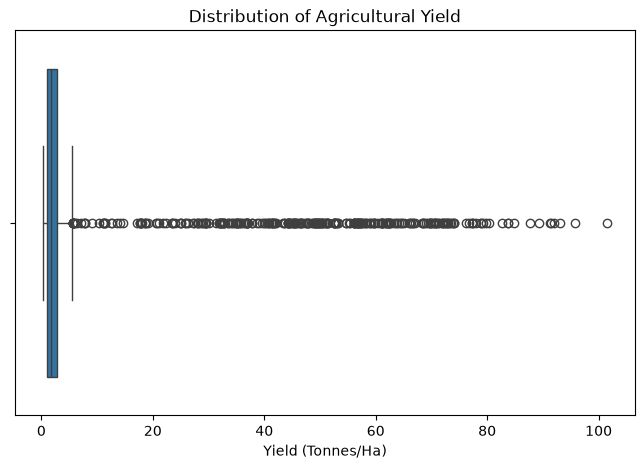

In [24]:
plt.figure(figsize=(8,5))

sns.boxplot(x=df["Yield_Tonnes_Ha"])

plt.title("Distribution of Agricultural Yield")
plt.xlabel("Yield (Tonnes/Ha)")
plt.show()

In [25]:
df["Yield_Tonnes_Ha"].describe()

count    4000.000000
mean        5.242350
std        13.311549
min         0.300000
25%         1.050000
50%         1.740000
75%         2.830000
max       101.440000
Name: Yield_Tonnes_Ha, dtype: float64

In [26]:
df.dtypes
df.isnull().sum()
df["Yield_Tonnes_Ha"].describe()

count    4000.000000
mean        5.242350
std        13.311549
min         0.300000
25%         1.050000
50%         1.740000
75%         2.830000
max       101.440000
Name: Yield_Tonnes_Ha, dtype: float64

## 4. Seasonal Distribution

The first step of the analysis is to understand how the agricultural observations are distributed across different seasons.

This helps determine whether the dataset contains a reasonably comparable number of observations for Kharif, Rabi, and Zaid seasons.

In [27]:
season_counts = df["Season"].value_counts()

print(season_counts)

Season
Kharif    1779
Rabi      1627
Zaid       594
Name: count, dtype: int64


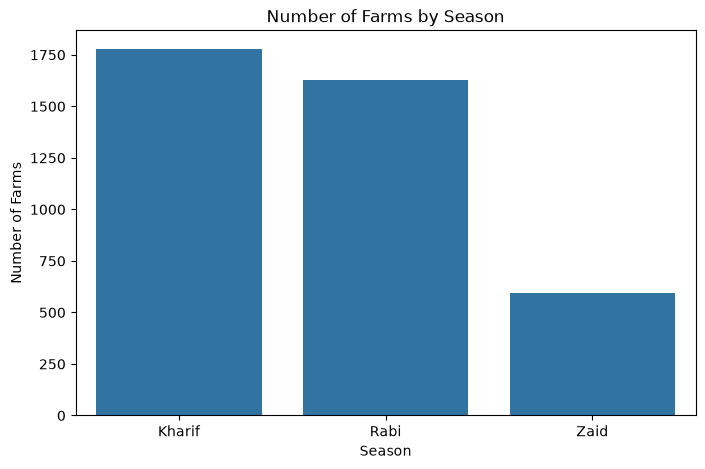

In [28]:
plt.figure(figsize=(8, 5))

sns.countplot(data=df, x="Season")

plt.title("Number of Farms by Season")
plt.xlabel("Season")
plt.ylabel("Number of Farms")

plt.show()

## 5. Seasonal Yield Analysis

### Question

How does average agricultural yield vary across Kharif, Rabi, and Zaid seasons?

Yield is one of the most important indicators of agricultural performance. Comparing average yield across seasons can help identify which seasonal conditions are associated with higher agricultural productivity.

In [29]:
season_yield = df.groupby("Season")["Yield_Tonnes_Ha"].mean()

print(season_yield)

Season
Kharif    5.628612
Rabi      5.039435
Zaid      4.641313
Name: Yield_Tonnes_Ha, dtype: float64


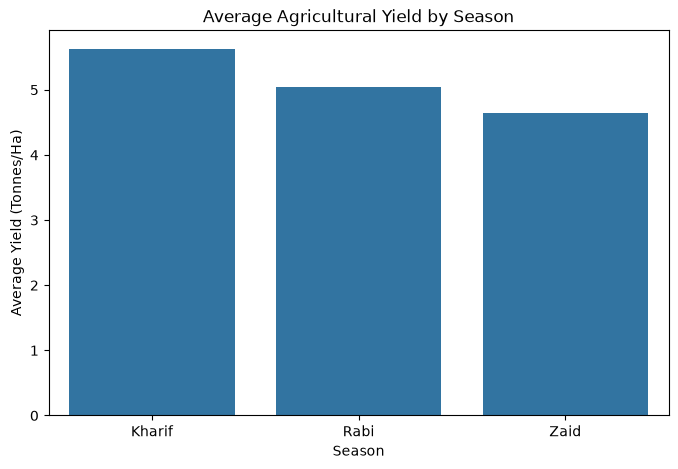

In [30]:
plt.figure(figsize=(8, 5))

sns.barplot(
    x=season_yield.index,
    y=season_yield.values
)

plt.title("Average Agricultural Yield by Season")
plt.xlabel("Season")
plt.ylabel("Average Yield (Tonnes/Ha)")

plt.show()

In [31]:
season_yield_stats = df.groupby("Season")["Yield_Tonnes_Ha"].agg(
    ["mean", "median", "min", "max"]
)

season_yield_stats

,mean,median,min,max
Season,,,,
Kharif,5.628612,1.94,0.3,101.44
Rabi,5.039435,1.67,0.3,93.13
Zaid,4.641313,1.46,0.3,64.76


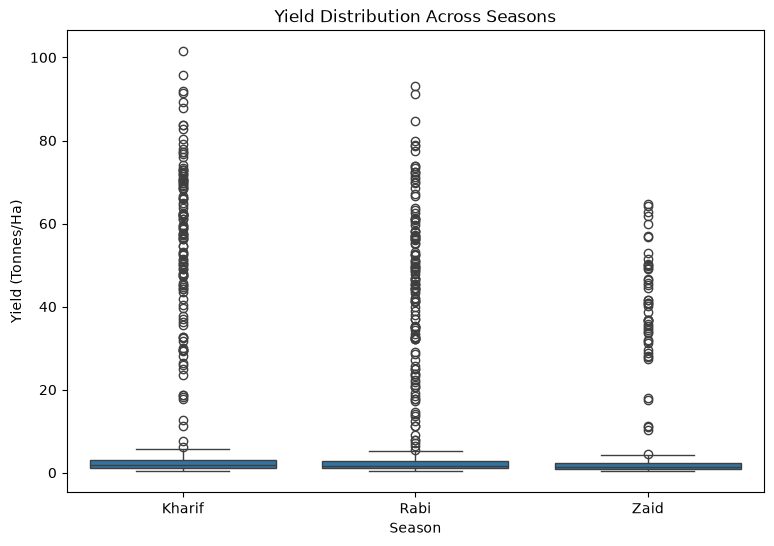

In [32]:
plt.figure(figsize=(9, 6))

sns.boxplot(
    data=df,
    x="Season",
    y="Yield_Tonnes_Ha"
)

plt.title("Yield Distribution Across Seasons")
plt.xlabel("Season")
plt.ylabel("Yield (Tonnes/Ha)")

plt.show()

## 6. Seasonal Profitability Analysis

### Question

How does agricultural profitability vary across different seasons?

Yield alone does not determine agricultural success. Production costs and market revenue also influence the final economic outcome. Therefore, seasonal profit is analyzed to understand which seasons provide better financial performance.

In [33]:
season_profit = df.groupby("Season")["Profit_INR"].mean()

print(season_profit)

Season
Kharif    178914.647555
Rabi       87689.470191
Zaid      -24804.824916
Name: Profit_INR, dtype: float64


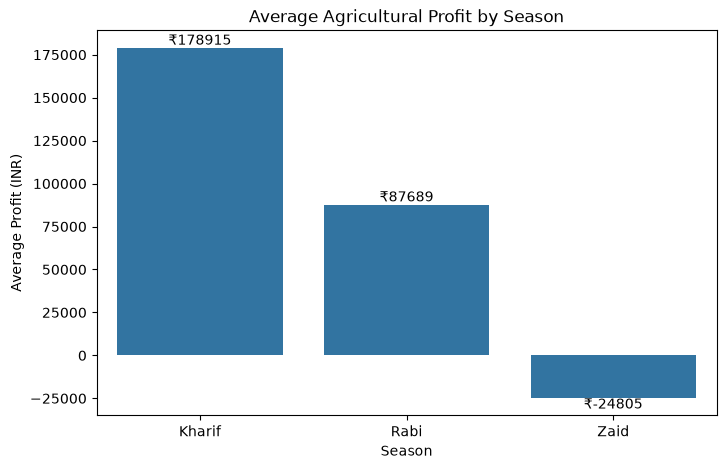

In [34]:
plt.figure(figsize=(8, 5))

ax = sns.barplot(
    x=season_profit.index,
    y=season_profit.values
)

plt.title("Average Agricultural Profit by Season")
plt.xlabel("Season")
plt.ylabel("Average Profit (INR)")

# Add values on top of each bar
for container in ax.containers:
    ax.bar_label(container, fmt="₹%.0f")

plt.show()

## 7. Crop-wise Yield Analysis

### Question

How does average agricultural yield vary across different crops?

Comparing crop-wise yield helps identify which crops achieve higher productivity in the available agricultural conditions.

In [35]:
crop_yield = df.groupby("Crop")["Yield_Tonnes_Ha"].mean().sort_values(ascending=False)

print(crop_yield)

Crop
Sugarcane    46.642361
Maize         2.710036
Rice          2.431304
Wheat         2.108013
Chilli        1.542767
Groundnut     1.322901
Cotton        1.229783
Pulses        0.921512
Name: Yield_Tonnes_Ha, dtype: float64


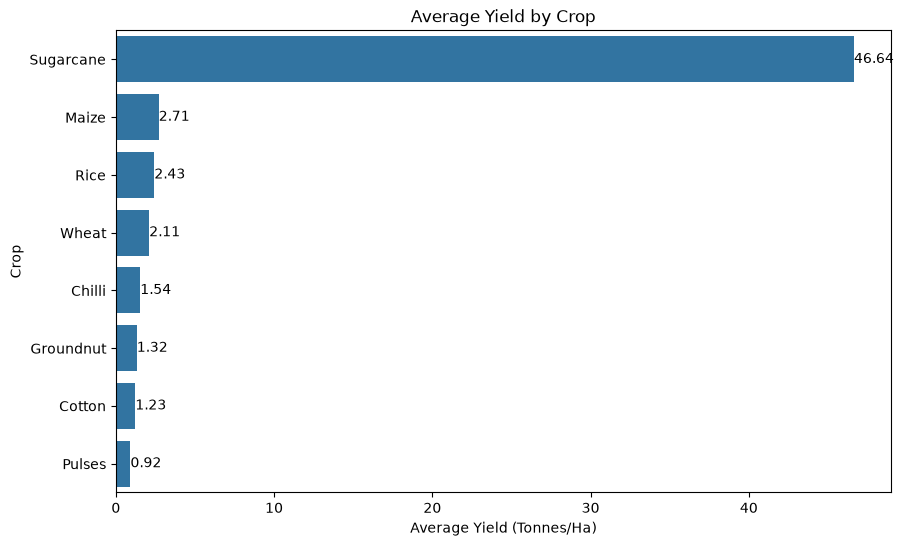

In [36]:
plt.figure(figsize=(10, 6))

ax = sns.barplot(
    x=crop_yield.values,
    y=crop_yield.index
)

plt.title("Average Yield by Crop")
plt.xlabel("Average Yield (Tonnes/Ha)")
plt.ylabel("Crop")

for container in ax.containers:
    ax.bar_label(container, fmt="%.2f")

plt.show()

In [37]:
crop_season_yield = df.pivot_table(
    values="Yield_Tonnes_Ha",
    index="Crop",
    columns="Season",
    aggfunc="mean"
)

crop_season_yield

Season,Kharif,Rabi,Zaid
Crop,,,
Chilli,1.731459,1.465031,1.195312
Cotton,1.374512,1.198358,0.960217
Groundnut,1.484974,1.233164,1.037778
Maize,2.966410,2.603648,2.290952
Pulses,1.036063,0.875962,0.669677
Rice,2.698376,2.322847,1.900490
Sugarcane,53.459120,43.286124,38.423922
Wheat,2.253664,2.057468,1.748588


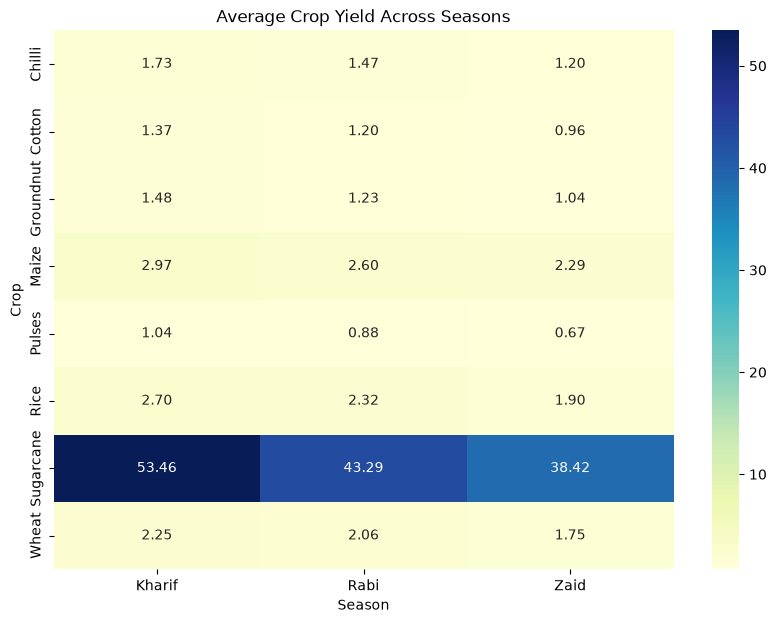

In [38]:
plt.figure(figsize=(10, 7))

sns.heatmap(
    crop_season_yield,
    annot=True,
    fmt=".2f",
    cmap="YlGnBu"
)

plt.title("Average Crop Yield Across Seasons")
plt.xlabel("Season")
plt.ylabel("Crop")

plt.show()

In [39]:
crop_yield = df.groupby("Crop")["Yield_Tonnes_Ha"].mean().sort_values(ascending=False)
print(crop_yield)

Crop
Sugarcane    46.642361
Maize         2.710036
Rice          2.431304
Wheat         2.108013
Chilli        1.542767
Groundnut     1.322901
Cotton        1.229783
Pulses        0.921512
Name: Yield_Tonnes_Ha, dtype: float64


In [40]:
crop_season_yield = df.pivot_table(
    values="Yield_Tonnes_Ha",
    index="Crop",
    columns="Season",
    aggfunc="mean"
)

crop_season_yield

Season,Kharif,Rabi,Zaid
Crop,,,
Chilli,1.731459,1.465031,1.195312
Cotton,1.374512,1.198358,0.960217
Groundnut,1.484974,1.233164,1.037778
Maize,2.966410,2.603648,2.290952
Pulses,1.036063,0.875962,0.669677
Rice,2.698376,2.322847,1.900490
Sugarcane,53.459120,43.286124,38.423922
Wheat,2.253664,2.057468,1.748588


### Interpretation

The heatmap shows a consistent seasonal pattern across all crops, with average yield generally highest during the Kharif season, followed by Rabi and Zaid. This suggests that seasonal conditions have an important influence on agricultural productivity.

Maize and Rice show relatively high yields among the non-Sugarcane crops, while Pulses and Cotton show comparatively lower yields.

Sugarcane has substantially higher yield values than the other crops in the dataset. Therefore, Sugarcane acts as a major contributor to the overall skewness of the yield distribution and should be considered separately when interpreting overall yield statistics.

The consistent pattern of Kharif > Rabi > Zaid across the crops indicates that the seasonal difference is not limited to a single crop category.

## 8. Relationship Between Rainfall and Yield

### Question

Is there a relationship between rainfall and agricultural yield?

Rainfall is an important environmental factor in agriculture. This analysis investigates whether changes in rainfall are associated with differences in crop yield.

In [41]:
rainfall_yield_corr = df["Rainfall_mm"].corr(df["Yield_Tonnes_Ha"])

print("Correlation between Rainfall and Yield:", rainfall_yield_corr)

Correlation between Rainfall and Yield: 0.030950993551650857


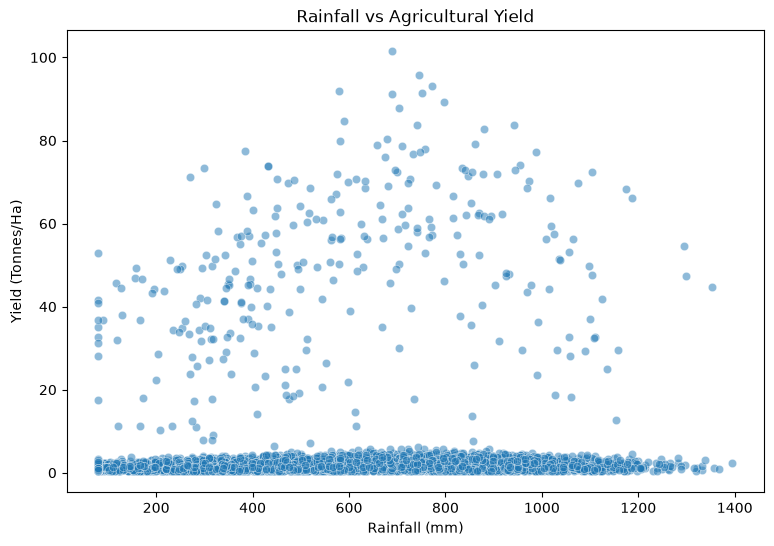

In [42]:
plt.figure(figsize=(9, 6))

sns.scatterplot(
    data=df,
    x="Rainfall_mm",
    y="Yield_Tonnes_Ha",
    alpha=0.5
)

plt.title("Rainfall vs Agricultural Yield")
plt.xlabel("Rainfall (mm)")
plt.ylabel("Yield (Tonnes/Ha)")

plt.show()

### Interpretation

The correlation coefficient between rainfall and agricultural yield is approximately 0.03, which is very close to zero. This indicates that there is no strong linear relationship between rainfall and yield in the overall dataset.

The scatter plot also shows considerable variation in yield across different rainfall levels rather than a clear increasing or decreasing trend.

Therefore, rainfall alone does not appear to be a strong predictor of agricultural yield in this dataset. Other factors such as crop type, season, soil characteristics, irrigation, fertilizer usage, and environmental conditions may contribute to yield differences.

In [43]:
non_sugarcane = df[df["Crop"] != "Sugarcane"]

print(
    "Correlation excluding Sugarcane:",
    non_sugarcane["Rainfall_mm"].corr(non_sugarcane["Yield_Tonnes_Ha"])
)

Correlation excluding Sugarcane: 0.15787572810106806


## 9. Irrigation Method and Water Usage

### Question

How does water usage vary across different irrigation methods?

Different irrigation methods may require different amounts of water. Comparing average water usage can help identify differences in resource utilization across irrigation practices.

In [44]:
irrigation_water = (
    df.groupby("Irrigation_Method")["Water_Used_m3"]
    .mean()
    .sort_values()
)

print(irrigation_water)

Irrigation_Method
Rainfed      3549.554275
Drip         5918.747541
Sprinkler    6208.258856
Flood        8026.472519
Name: Water_Used_m3, dtype: float64


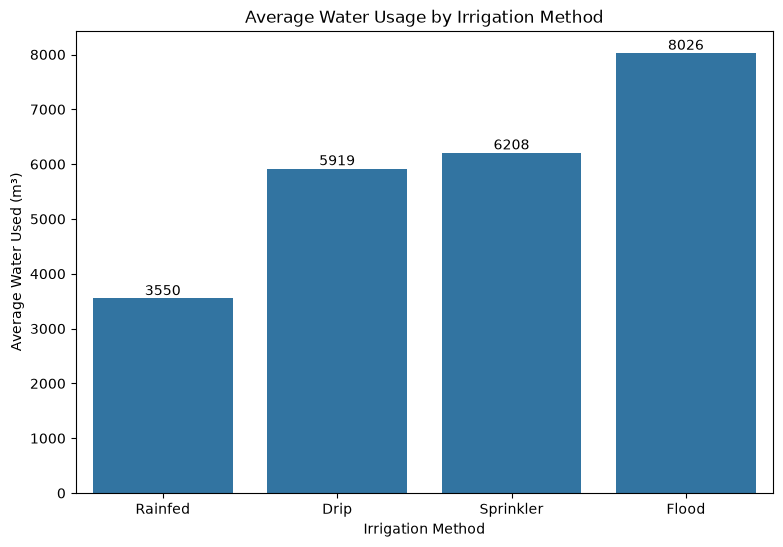

In [45]:
plt.figure(figsize=(9, 6))

ax = sns.barplot(
    x=irrigation_water.index,
    y=irrigation_water.values
)

plt.title("Average Water Usage by Irrigation Method")
plt.xlabel("Irrigation Method")
plt.ylabel("Average Water Used (m³)")

for container in ax.containers:
    ax.bar_label(container, fmt="%.0f")

plt.show()

In [46]:
irrigation_efficiency = (
    df.groupby("Irrigation_Method")["Water_Efficiency_t_per_1000m3"]
    .mean()
    .sort_values(ascending=False)
)

print(irrigation_efficiency)

Irrigation_Method
Rainfed      7.563784
Drip         6.267129
Sprinkler    4.669805
Flood        3.438853
Name: Water_Efficiency_t_per_1000m3, dtype: float64


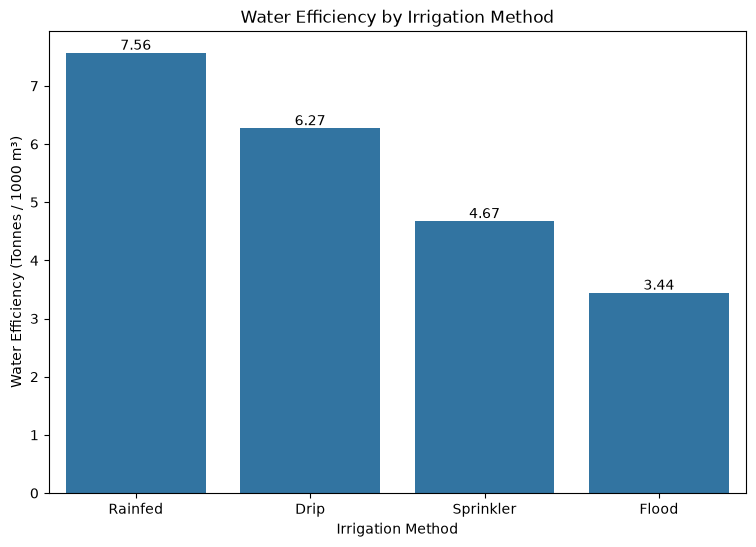

In [47]:
plt.figure(figsize=(9, 6))

ax = sns.barplot(
    x=irrigation_efficiency.index,
    y=irrigation_efficiency.values
)

plt.title("Water Efficiency by Irrigation Method")
plt.xlabel("Irrigation Method")
plt.ylabel("Water Efficiency (Tonnes / 1000 m³)")

for container in ax.containers:
    ax.bar_label(container, fmt="%.2f")

plt.show()

In [48]:
irrigation_water = (
    df.groupby("Irrigation_Method")["Water_Used_m3"]
    .mean()
    .sort_values()
)

print(irrigation_water)

Irrigation_Method
Rainfed      3549.554275
Drip         5918.747541
Sprinkler    6208.258856
Flood        8026.472519
Name: Water_Used_m3, dtype: float64


In [49]:
irrigation_efficiency = (
    df.groupby("Irrigation_Method")["Water_Efficiency_t_per_1000m3"]
    .mean()
    .sort_values(ascending=False)
)

print(irrigation_efficiency)

Irrigation_Method
Rainfed      7.563784
Drip         6.267129
Sprinkler    4.669805
Flood        3.438853
Name: Water_Efficiency_t_per_1000m3, dtype: float64


### Interpretation

The analysis shows substantial differences in water usage and water efficiency across irrigation categories.

Flood irrigation records the highest average water usage at approximately 8,026 m³, while Rainfed farms record the lowest average usage at approximately 3,550 m³.

The water-efficiency analysis shows the opposite pattern. Rainfed farms have the highest average water-efficiency value of approximately 7.56 tonnes per 1,000 m³, while Flood irrigation has the lowest value at approximately 3.44 tonnes per 1,000 m³.

These results indicate that higher water usage does not necessarily correspond to higher water efficiency in the dataset. However, these are observational comparisons and may also be influenced by factors such as crop type, season, farm size, and environmental conditions.

## 10. Correlation Analysis

Correlation analysis is used to examine the relationships between numerical variables in the agricultural dataset.

The analysis focuses on environmental conditions, resource usage, agricultural productivity, and economic performance.

In [50]:
correlation_columns = [
    "Farm_Area_Hectares",
    "Rainfall_mm",
    "Avg_Temperature_C",
    "Humidity_pct",
    "Sunlight_Hours_Day",
    "Soil_pH",
    "Soil_Moisture_pct",
    "Nitrogen_kg_ha",
    "Phosphorus_kg_ha",
    "Potassium_kg_ha",
    "Fertilizer_kg_ha",
    "Pesticide_Litre_ha",
    "Yield_Tonnes_Ha",
    "Production_Tonnes",
    "Market_Price_INR_Tonne",
    "Total_Cost_INR",
    "Revenue_INR",
    "Profit_INR",
    "Water_Used_m3",
    "Water_Efficiency_t_per_1000m3"
]

correlation_matrix = df[correlation_columns].corr()

correlation_matrix

,Farm_Area_Hectares,Rainfall_mm,Avg_Temperature_C,Humidity_pct,Sunlight_Hours_Day,Soil_pH,Soil_Moisture_pct,Nitrogen_kg_ha,Phosphorus_kg_ha,Potassium_kg_ha,Fertilizer_kg_ha,Pesticide_Litre_ha,Yield_Tonnes_Ha,Production_Tonnes,Market_Price_INR_Tonne,Total_Cost_INR,Revenue_INR,Profit_INR,Water_Used_m3,Water_Efficiency_t_per_1000m3
Farm_Area_Hectares,1.000000,0.007256,0.036870,0.000471,0.001821,0.009857,0.004033,0.013658,-0.006625,0.000195,0.014975,-0.005207,0.030203,0.197842,-0.021571,0.962211,0.543364,0.115241,0.576015,0.028930
Rainfall_mm,0.007256,1.000000,0.198492,0.521069,-0.362779,0.016657,0.508941,0.007460,0.020940,0.031373,0.024602,0.004058,0.030951,0.024447,0.000639,0.013041,0.098146,0.107648,0.002240,0.058102
Avg_Temperature_C,0.036870,0.198492,1.000000,0.138136,-0.033863,0.029988,0.084001,0.018707,0.008508,0.022993,0.015861,0.006657,0.009996,0.007346,0.002951,0.041030,0.026703,0.009043,0.022995,0.006534
Humidity_pct,0.000471,0.521069,0.138136,1.000000,-0.297298,0.028447,0.446470,0.001198,-0.005963,-0.003070,0.024623,-0.004028,0.012297,0.003614,0.000262,0.006023,0.057358,0.063775,-0.002086,0.026169
Sunlight_Hours_Day,0.001821,-0.362779,-0.033863,-0.297298,1.000000,-0.017806,-0.302846,0.009920,0.001544,-0.014407,-0.013073,-0.017238,-0.015341,-0.023504,-0.000696,-0.000655,-0.047216,-0.054822,-0.005717,-0.021386
Soil_pH,0.009857,0.016657,0.029988,0.028447,-0.017806,1.000000,0.031183,0.006286,0.016620,-0.019407,-0.010591,-0.010135,-0.020672,-0.012512,0.022226,0.005302,-0.008798,-0.013145,-0.022859,-0.010087
Soil_Moisture_pct,0.004033,0.508941,0.084001,0.446470,-0.302846,0.031183,1.000000,0.008884,0.013406,0.007796,0.008782,-0.023159,0.010999,0.004787,0.016914,0.002741,0.079380,0.091281,0.003183,0.027776
Nitrogen_kg_ha,0.013658,0.007460,0.018707,0.001198,0.009920,0.006286,0.008884,1.000000,0.010199,0.010490,-0.032440,0.014280,0.053149,0.048182,-0.022595,0.011900,0.078252,0.085016,0.022127,0.054896
Phosphorus_kg_ha,-0.006625,0.020940,0.008508,-0.005963,0.001544,0.016620,0.013406,0.010199,1.000000,0.002847,0.012905,-0.029942,0.047941,0.034957,-0.005174,-0.016508,0.034940,0.049747,-0.000752,0.057129
Potassium_kg_ha,0.000195,0.031373,0.022993,-0.003070,-0.014407,-0.019407,0.007796,0.010490,0.002847,1.000000,0.017254,-0.004675,0.003382,0.004472,0.007572,0.003431,0.028278,0.031192,0.001667,0.006575


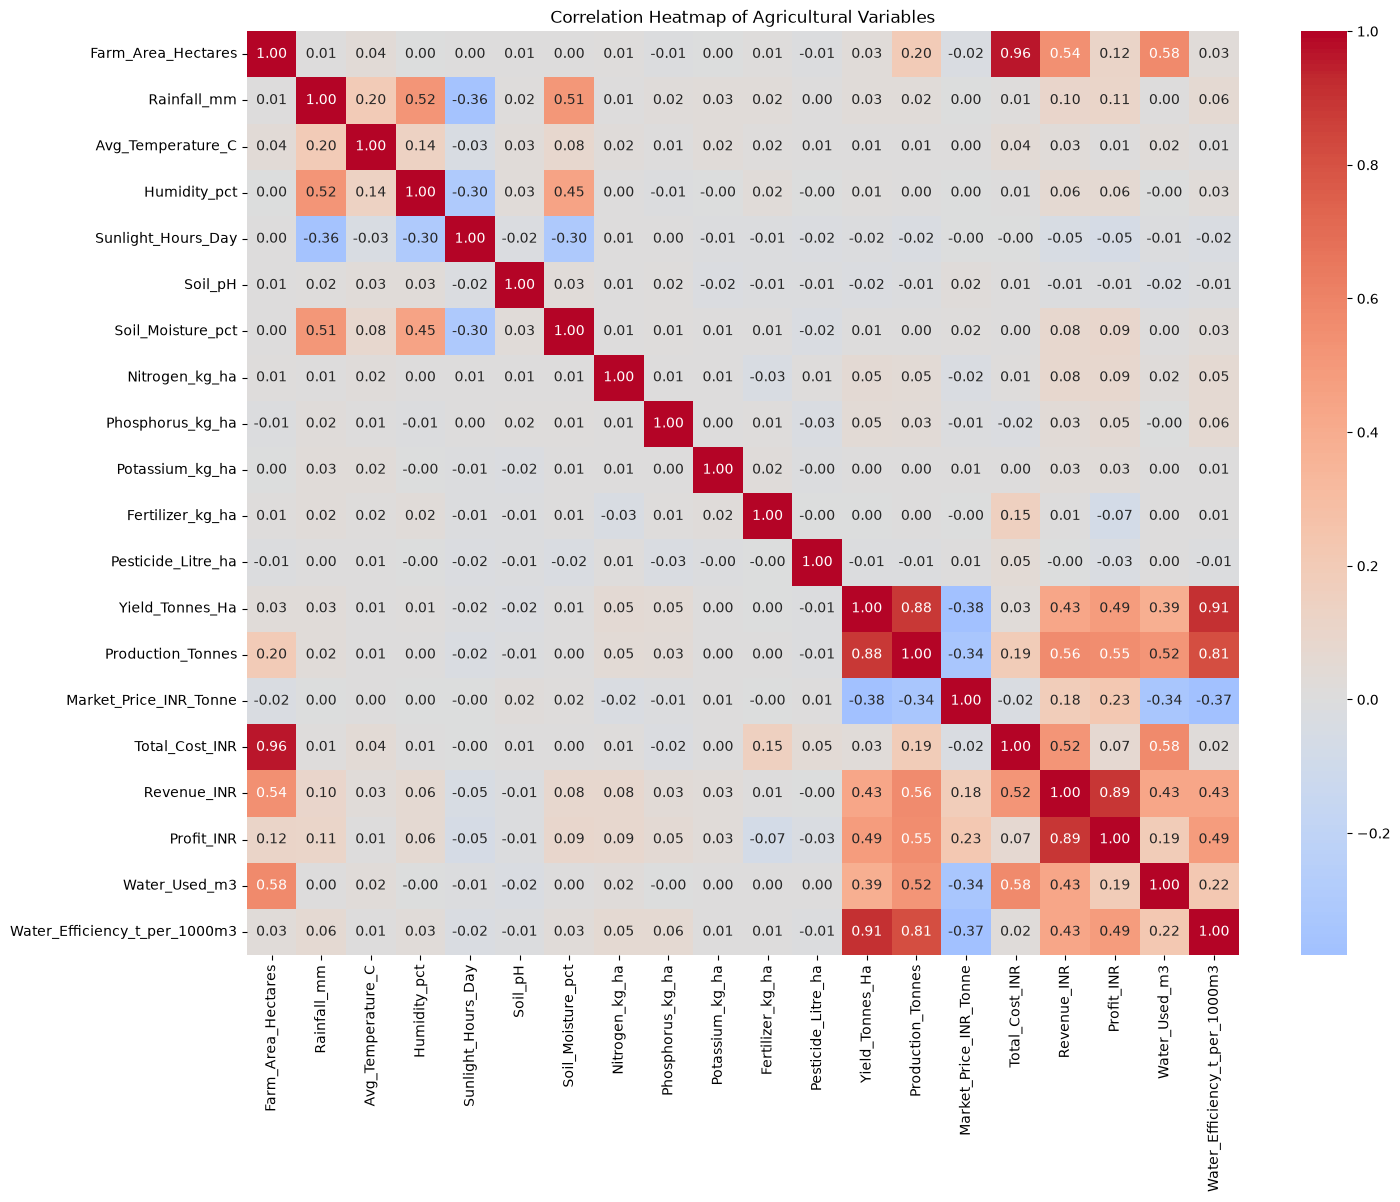

In [51]:
plt.figure(figsize=(16, 12))

sns.heatmap(
    correlation_matrix,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    center=0
)

plt.title("Correlation Heatmap of Agricultural Variables")
plt.show()

## 11. Strongest Numerical Relationships

To identify the most prominent relationships in the dataset, the correlation matrix is examined to find pairs of numerical variables with the strongest absolute correlation values.

In [52]:
corr_pairs = correlation_matrix.unstack()

corr_pairs = corr_pairs[corr_pairs.index.get_level_values(0) != corr_pairs.index.get_level_values(1)]

corr_pairs = corr_pairs.sort_values(key=abs, ascending=False)

corr_pairs.head(15)

Farm_Area_Hectares             Total_Cost_INR                   0.962211
Total_Cost_INR                 Farm_Area_Hectares               0.962211
Water_Efficiency_t_per_1000m3  Yield_Tonnes_Ha                  0.912568
Yield_Tonnes_Ha                Water_Efficiency_t_per_1000m3    0.912568
Profit_INR                     Revenue_INR                      0.887331
Revenue_INR                    Profit_INR                       0.887331
Yield_Tonnes_Ha                Production_Tonnes                0.882813
Production_Tonnes              Yield_Tonnes_Ha                  0.882813
Water_Efficiency_t_per_1000m3  Production_Tonnes                0.812143
Production_Tonnes              Water_Efficiency_t_per_1000m3    0.812143
Farm_Area_Hectares             Water_Used_m3                    0.576015
Water_Used_m3                  Farm_Area_Hectares               0.576015
                               Total_Cost_INR                   0.575978
Total_Cost_INR                 Water_Used_m3       

In [53]:
corr_pairs = correlation_matrix.where(
    np.triu(np.ones(correlation_matrix.shape), k=1).astype(bool)
)

corr_pairs = corr_pairs.stack().sort_values(
    key=abs,
    ascending=False
)

corr_pairs.head(15)

Farm_Area_Hectares  Total_Cost_INR                   0.962211
Yield_Tonnes_Ha     Water_Efficiency_t_per_1000m3    0.912568
Revenue_INR         Profit_INR                       0.887331
Yield_Tonnes_Ha     Production_Tonnes                0.882813
Production_Tonnes   Water_Efficiency_t_per_1000m3    0.812143
Farm_Area_Hectares  Water_Used_m3                    0.576015
Total_Cost_INR      Water_Used_m3                    0.575978
Production_Tonnes   Revenue_INR                      0.563505
                    Profit_INR                       0.554172
Farm_Area_Hectares  Revenue_INR                      0.543364
Rainfall_mm         Humidity_pct                     0.521069
Total_Cost_INR      Revenue_INR                      0.520709
Production_Tonnes   Water_Used_m3                    0.515557
Rainfall_mm         Soil_Moisture_pct                0.508941
Profit_INR          Water_Efficiency_t_per_1000m3    0.489487
dtype: float64

In [54]:
profit_correlations = (
    correlation_matrix["Profit_INR"]
    .drop("Profit_INR")
    .sort_values(key=abs, ascending=False)
)

profit_correlations

Revenue_INR                      0.887331
Production_Tonnes                0.554172
Water_Efficiency_t_per_1000m3    0.489487
Yield_Tonnes_Ha                  0.488466
Market_Price_INR_Tonne           0.225119
Water_Used_m3                    0.190278
Farm_Area_Hectares               0.115241
Rainfall_mm                      0.107648
Soil_Moisture_pct                0.091281
Nitrogen_kg_ha                   0.085016
Fertilizer_kg_ha                -0.073542
Total_Cost_INR                   0.068356
Humidity_pct                     0.063775
Sunlight_Hours_Day              -0.054822
Phosphorus_kg_ha                 0.049747
Potassium_kg_ha                  0.031192
Pesticide_Litre_ha              -0.025705
Soil_pH                         -0.013145
Avg_Temperature_C                0.009043
Name: Profit_INR, dtype: float64

In [55]:
season_economics = df.groupby("Season")[
    ["Total_Cost_INR", "Revenue_INR", "Profit_INR"]
].mean()

season_economics

,Total_Cost_INR,Revenue_INR,Profit_INR
Season,,,
Kharif,531804.408094,710719.055649,178914.647555
Rabi,513836.578365,601526.048556,87689.470191
Zaid,543976.728956,519171.904040,-24804.824916


In [56]:
profit_correlations = (
    correlation_matrix["Profit_INR"]
    .drop("Profit_INR")
    .sort_values(key=abs, ascending=False)
)

profit_correlations

Revenue_INR                      0.887331
Production_Tonnes                0.554172
Water_Efficiency_t_per_1000m3    0.489487
Yield_Tonnes_Ha                  0.488466
Market_Price_INR_Tonne           0.225119
Water_Used_m3                    0.190278
Farm_Area_Hectares               0.115241
Rainfall_mm                      0.107648
Soil_Moisture_pct                0.091281
Nitrogen_kg_ha                   0.085016
Fertilizer_kg_ha                -0.073542
Total_Cost_INR                   0.068356
Humidity_pct                     0.063775
Sunlight_Hours_Day              -0.054822
Phosphorus_kg_ha                 0.049747
Potassium_kg_ha                  0.031192
Pesticide_Litre_ha              -0.025705
Soil_pH                         -0.013145
Avg_Temperature_C                0.009043
Name: Profit_INR, dtype: float64

In [57]:
season_economics = df.groupby("Season")[
    ["Total_Cost_INR", "Revenue_INR", "Profit_INR"]
].mean()

season_economics

,Total_Cost_INR,Revenue_INR,Profit_INR
Season,,,
Kharif,531804.408094,710719.055649,178914.647555
Rabi,513836.578365,601526.048556,87689.470191
Zaid,543976.728956,519171.904040,-24804.824916


In [58]:
profit_check = df["Revenue_INR"] - df["Total_Cost_INR"]

print("Maximum difference between calculated and recorded profit:",
      (profit_check - df["Profit_INR"]).abs().max())

Maximum difference between calculated and recorded profit: 0


## 12. Seasonal Profit Margin Analysis

Profit margin measures the proportion of revenue that remains as profit after accounting for costs.

It provides a relative measure of profitability and allows better comparison between seasons with different revenue levels.

In [59]:
season_economics["Profit_Margin_pct"] = (
    season_economics["Profit_INR"] /
    season_economics["Revenue_INR"]
) * 100

season_economics

,Total_Cost_INR,Revenue_INR,Profit_INR,Profit_Margin_pct
Season,,,,
Kharif,531804.408094,710719.055649,178914.647555,25.173751
Rabi,513836.578365,601526.048556,87689.470191,14.577834
Zaid,543976.728956,519171.904040,-24804.824916,-4.777767


<Figure size 1000x600 with 0 Axes>

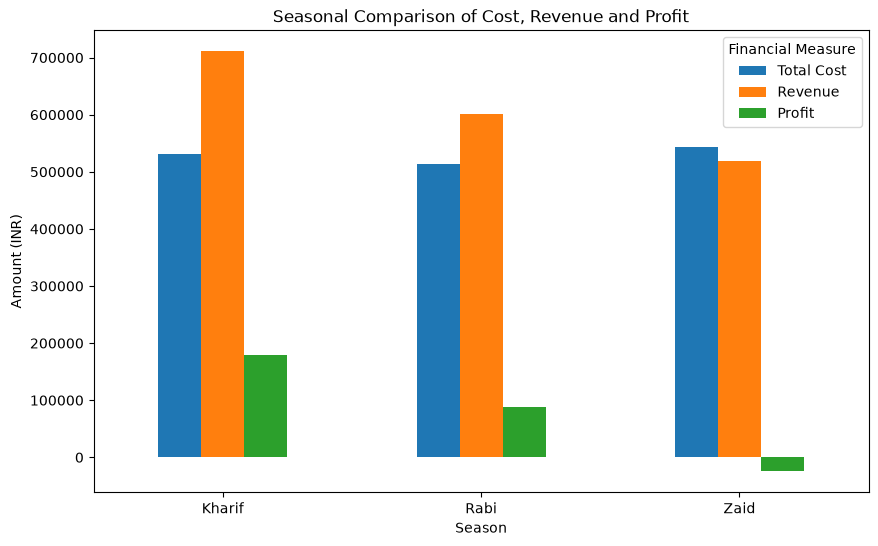

In [60]:
plt.figure(figsize=(10, 6))

season_economics[
    ["Total_Cost_INR", "Revenue_INR", "Profit_INR"]
].plot(
    kind="bar",
    figsize=(10, 6)
)

plt.title("Seasonal Comparison of Cost, Revenue and Profit")
plt.xlabel("Season")
plt.ylabel("Amount (INR)")
plt.xticks(rotation=0)

plt.legend(
    ["Total Cost", "Revenue", "Profit"],
    title="Financial Measure"
)

plt.show()

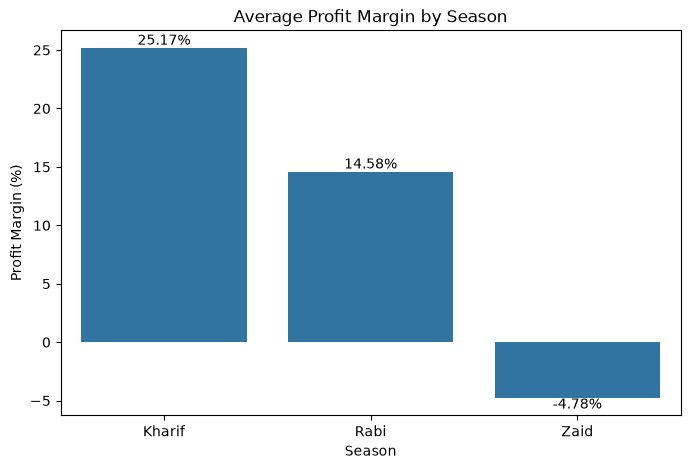

In [61]:
plt.figure(figsize=(8, 5))

ax = sns.barplot(
    x=season_economics.index,
    y=season_economics["Profit_Margin_pct"].values
)

plt.title("Average Profit Margin by Season")
plt.xlabel("Season")
plt.ylabel("Profit Margin (%)")

for container in ax.containers:
    ax.bar_label(container, fmt="%.2f%%")

plt.show()

### Interpretation

The seasonal profitability analysis shows substantial differences in financial performance.

Kharif has the highest average profit margin of approximately 25.17%, indicating that a relatively larger proportion of its revenue remains as profit after accounting for costs.

Rabi has a positive average profit margin of approximately 14.58%, but its profitability is lower than Kharif.

Zaid records a negative average profit margin of approximately -4.78%. Its revenue-to-cost ratio is also below 1, indicating that the average revenue generated during this season does not fully cover the average production cost.

Overall, Kharif shows the strongest economic performance among the three seasons, while Zaid presents the greatest profitability challenge in the dataset.

In [62]:
season_economics["Revenue_Cost_Ratio"] = (
    season_economics["Revenue_INR"] /
    season_economics["Total_Cost_INR"]
)

season_economics[
    ["Total_Cost_INR", "Revenue_INR", "Profit_INR",
     "Profit_Margin_pct", "Revenue_Cost_Ratio"]
]

,Total_Cost_INR,Revenue_INR,Profit_INR,Profit_Margin_pct,Revenue_Cost_Ratio
Season,,,,,
Kharif,531804.408094,710719.055649,178914.647555,25.173751,1.336429
Rabi,513836.578365,601526.048556,87689.470191,14.577834,1.170656
Zaid,543976.728956,519171.904040,-24804.824916,-4.777767,0.954401


In [63]:
profit_check = df["Revenue_INR"] - df["Total_Cost_INR"]

print(
    "Maximum difference between calculated and recorded profit:",
    (profit_check - df["Profit_INR"]).abs().max()
)

Maximum difference between calculated and recorded profit: 0


In [64]:
season_economics["Profit_Margin_pct"] = (
    season_economics["Profit_INR"] /
    season_economics["Revenue_INR"]
) * 100

season_economics["Revenue_Cost_Ratio"] = (
    season_economics["Revenue_INR"] /
    season_economics["Total_Cost_INR"]
)

season_economics

,Total_Cost_INR,Revenue_INR,Profit_INR,Profit_Margin_pct,Revenue_Cost_Ratio
Season,,,,,
Kharif,531804.408094,710719.055649,178914.647555,25.173751,1.336429
Rabi,513836.578365,601526.048556,87689.470191,14.577834,1.170656
Zaid,543976.728956,519171.904040,-24804.824916,-4.777767,0.954401


## 13. Relationship Between Production and Revenue

Agricultural production is expected to influence the amount of output available for sale. This analysis examines whether higher production is associated with higher revenue.

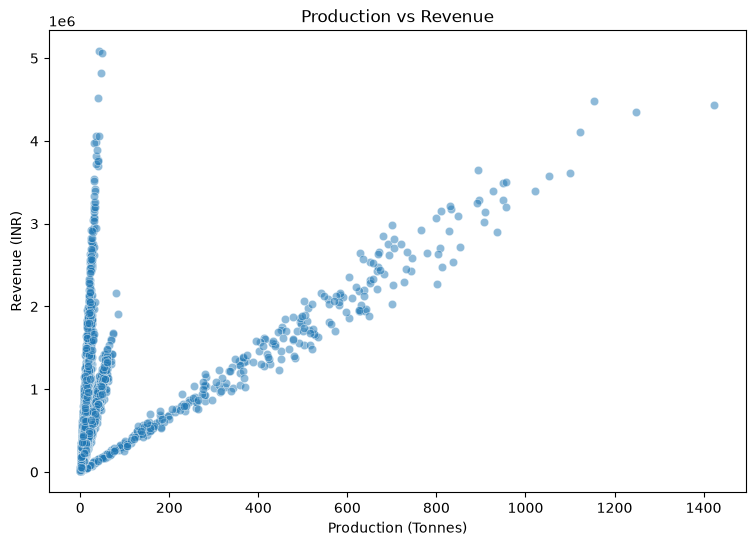

In [65]:
plt.figure(figsize=(9, 6))

sns.scatterplot(
    data=df,
    x="Production_Tonnes",
    y="Revenue_INR",
    alpha=0.5
)

plt.title("Production vs Revenue")
plt.xlabel("Production (Tonnes)")
plt.ylabel("Revenue (INR)")

plt.show()

In [66]:
production_revenue_corr = df["Production_Tonnes"].corr(
    df["Revenue_INR"]
)

print(
    "Correlation between Production and Revenue:",
    production_revenue_corr
)

Correlation between Production and Revenue: 0.563505034256987


### Interpretation

The scatter plot indicates a moderate positive relationship between agricultural production and revenue. The correlation coefficient of approximately 0.56 suggests that higher production is generally associated with higher revenue.

However, the relationship is not perfectly linear. Considerable variation in revenue can be observed for similar production levels, indicating that production alone does not determine revenue. Factors such as market price, crop type, and season may also contribute to differences in revenue.

Therefore, increasing production may support higher revenue, but the economic outcome also depends on market and agricultural conditions.

In [67]:
crop_price = (
    df.groupby("Crop")["Market_Price_INR_Tonne"]
    .mean()
    .sort_values(ascending=False)
)

print(crop_price)

Crop
Chilli       103372.941748
Pulses        71431.608871
Cotton        67921.108268
Groundnut     56310.061321
Wheat         23829.425081
Rice          22023.128986
Maize         20990.549909
Sugarcane      3490.252459
Name: Market_Price_INR_Tonne, dtype: float64


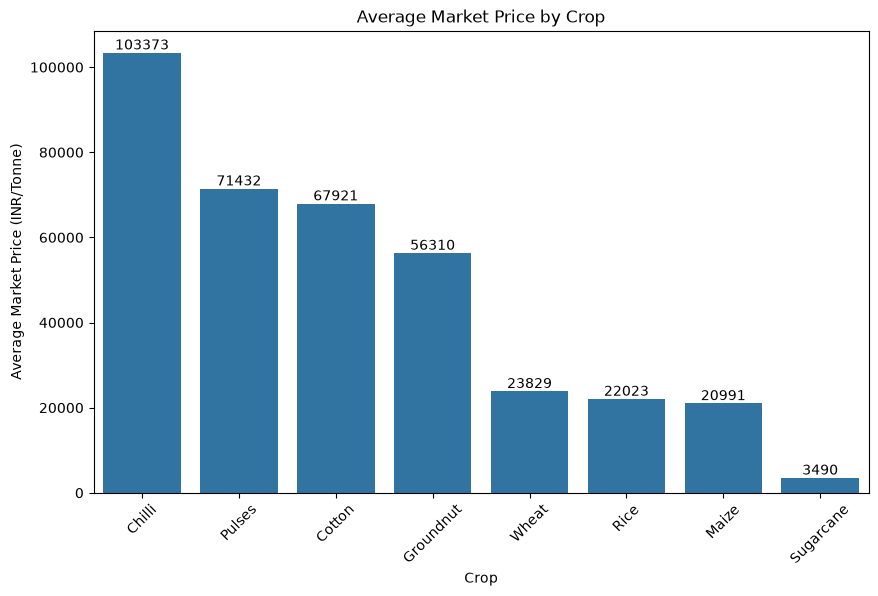

In [68]:
plt.figure(figsize=(10, 6))

ax = sns.barplot(
    x=crop_price.index,
    y=crop_price.values
)

plt.title("Average Market Price by Crop")
plt.xlabel("Crop")
plt.ylabel("Average Market Price (INR/Tonne)")
plt.xticks(rotation=45)

for container in ax.containers:
    ax.bar_label(container, fmt="%.0f")

plt.show()